# Assignment 1

## Anastasia Dobrynina
***

1. Choose a long text, a novel, in Russian or in English
2. Lemmatize the novel. -- 1 point
3. Choose a word from the lemmatized novel that is common for that novel and extract from the lemmatized novel all its children (all its syntactic dependencies) and all the children of its children (secondary dependencies). -- 2 points
4. Create a graph, depicting the result of (3). At the center of the graph would be your chosen word, around it all its dependencies, around those all their dependencies. Set the parameters: what the color and the size of the nodes and the width of the edges stands for. Choose a directed or a non-directed graph. Describe and justify your choices of the parameters. -- 2 points
5. Perform network analysis of the graph. Mesure the density, split the graph into communities etc. Describe and justify what and why you are doing. -- 2 points
6. Could you draw any meaningful conclusions from your analysis? Provide a short (a couple of sentences) answer. -- 1 point
***

In [1]:
# !pip install stanza

In [2]:
from collections import Counter
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import greedy_modularity_communities, modularity
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')
import stanza
stanza.download('ru')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/resources.json
INFO:stanza:Downloading default packages for language: ru (Russian) ...
INFO:stanza:File exists: /root/.cache/stanza/1.14.0/resources/ru/default.zip
INFO:stanza:Finished downloading models and saved to /root/.cache/stanza/1.14.0/resources


[['zip', 'default.zip']]

**Chosen text**: *Woe from Wit* (*Горе от ума*) by A. Griboedov, in Russian

In [3]:
filename = 'rus000047-griboyedov-gore-ot-uma.spoken-text.txt'

In [4]:
with open(filename, encoding='utf-8') as f:
    text = f.read()

In [5]:
text[:10]

'Светает!..'

### 2. Lemmatization

I use **stanza** because it:
* is multilingual
* gives high-quality results (neural models trained on SynTagRus)
* provides dependency parsing, which is needed for task 3, so the text is parsed only once

In [6]:
nlp = stanza.Pipeline('ru', processors='tokenize,pos,lemma,depparse')

INFO:stanza:Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


INFO:stanza:Downloaded file to /root/.cache/stanza/1.14.0/resources/resources.json
INFO:stanza:Loading these models for language: ru (Russian):
| Processor | Package            |
----------------------------------
| tokenize  | syntagrus          |
| pos       | syntagrus_charlm   |
| lemma     | syntagrus_nocharlm |
| depparse  | syntagrus_charlm   |

INFO:stanza:Using device: cpu
INFO:stanza:Loading: tokenize
INFO:stanza:Loading: pos
INFO:stanza:Loading: lemma
INFO:stanza:Loading: depparse
INFO:stanza:Done loading processors!


In [7]:
doc = nlp(text)

For the frequency list, stop-words and punctuation are removed, otherwiсe the top would consist only of function words.

In [8]:
sw = stopwords.words('russian')

In [9]:
# lemmas list without sws
lemmas = [w.lemma for s in doc.sentences for w in s.words if w.upos != 'PUNCT' and w.lemma not in sw]

In [10]:
# lemmatized text example
lemm_text = ' '.join(lemmas)
print(lemm_text[:100])

светать ах скоро ночь минуть вчера проситься спать отказ ждать друг нужный глаз глаз спать покудова 


In [11]:
# top common lemmas
print(Counter(lemmas).most_common(10))

[('весь', 80), ('ах', 52), ('сказать', 52), ('человек', 51), ('знать', 47), ('ум', 40), ('ваш', 39), ('бог', 36), ('мочь', 34), ('дать', 30)]


NB:

* stanza lemmatizes *все* as *весь*, so *весь* is not filtered by the NLTK stop-word list
* *ах* is not a stop-word, and its high frequency is informative: this is a play with emotional speech

### 3. Syntactic dependencies

I choose ***ум***: it is in the top-10 lemmas of the text and it is the key word of the title (*Горе от **ума***).

In [12]:
word = 'ум'

In [13]:
words = [w for s in doc.sentences for w in s.words]
freq = Counter(w.lemma for w in words)

Here stopwords are **not** removed: prepositions and pronouns are real syntactic dependents, and removing them would break the chain *ум → dependent → secondary dependent*

`d1` counts (head, dependent) pairs for direct dependents of *ум*; `d2` counts pairs for dependents of those dependents. Punctuation is skipped

In [14]:
d1, d2 = Counter(), Counter()  # (head, dependent) counts
for s in doc.sentences:
    for w in s.words:
        if w.lemma != word: continue
        for c in s.words:
            if c.head == w.id and c.upos != 'PUNCT':
                d1[(word, c.lemma)] += 1
                for g in s.words:
                    if g.head == c.id and g.upos != 'PUNCT':
                        d2[(c.lemma, g.lemma)] += 1


In [15]:
d1.most_common(5)

[(('ум', 'с'), 15),
 (('ум', 'на'), 4),
 (('ум', 'в'), 3),
 (('ум', 'наш'), 2),
 (('ум', 'по'), 2)]

In [16]:
d2.most_common(5)

[(('ничто', 'Проказ'), 1),
 (('ветер', 'и'), 1),
 (('признак', 'весь'), 1),
 (('признак', 'учение'), 1),
 (('привыкнуть', 'как'), 1)]

### 4. Graph

In [17]:
top1 = [c for (_, c), _ in d1.most_common(15) if c != word]  # keep graph readable

In [18]:
G = nx.DiGraph()
G.add_node(word, level=0)

In [19]:
for c in top1:
    G.add_node(c, level=1)
    G.add_edge(word, c, weight=d1[(word, c)])
for c in top1:
    kids = sorted(((g, n) for (h, g), n in d2.items() if h == c), key=lambda x: -x[1])[:5]
    for g, n in kids:
        if g not in G: G.add_node(g, level=2)
        G.add_edge(c, g, weight=n)

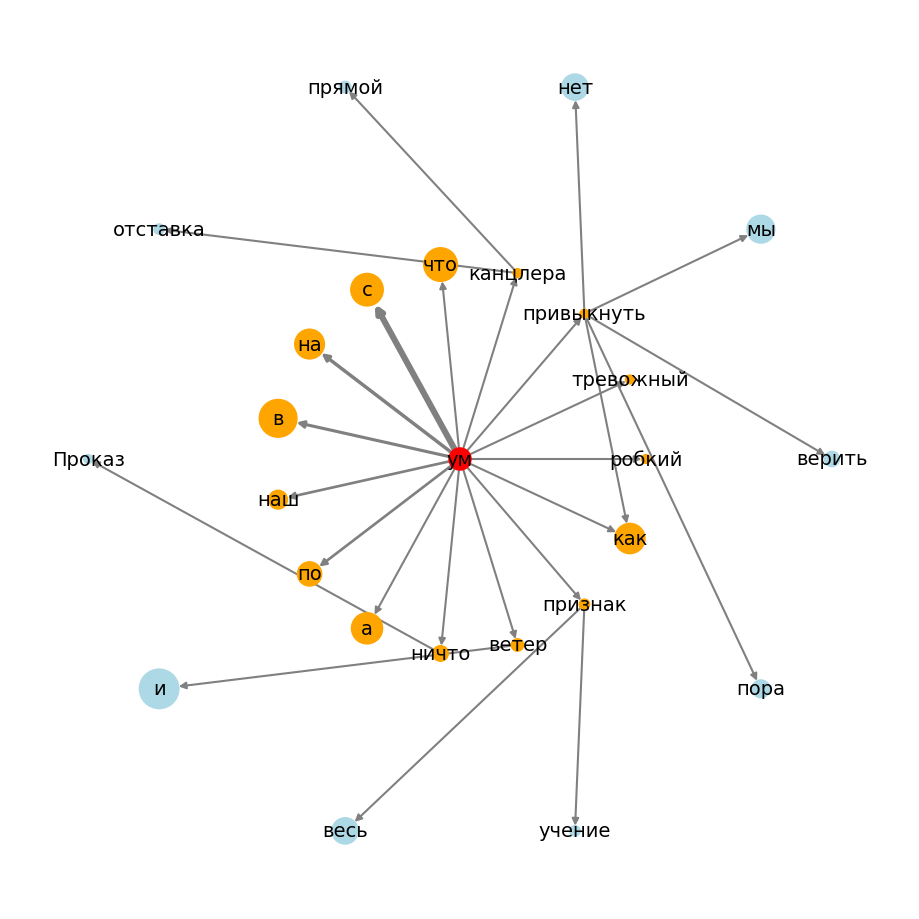

In [20]:
shells = [[n for n in G if G.nodes[n]['level'] == i] for i in range(3)]
pos = nx.shell_layout(G, shells)
colors = ['red', 'orange', 'lightblue']

plt.figure(figsize=(9, 9))
nx.draw(G, pos, with_labels=True, font_size=14,
        node_color=[colors[G.nodes[n]['level']] for n in G],
        node_size=[40 * freq[n] ** 0.5 for n in G],
        width=[0.5 + G[u][v]['weight'] ** 0.5 for u, v in G.edges],
        arrowsize=10,
        edge_color='gray')
plt.show()

I use a **directed** graph because syntactic dependency is asymmetric: arrows go from head to dependent.

- **Node color** = depth: red for *ум*, orange for its direct dependents, light blu for secondary ones
- **Node size** = lemma frequency in the novel (square-root scaled). It separates words that are just frequent overall (*и*, *в*) from ones specific to this context (*робкий*)
- **Edge width** = frequency of the head–dependent pair, i.e. strength of the association. The thickest edge, *ум → с*, shows the dominant construction *с ума*

Only the top 15 direct and top 5 secondary dependents per node are shown, to keep the graph readable

### 5. Network analysis

In [21]:
# top-10 nodes by number of neighbours
print(sorted(G.degree, key=lambda x: -x[1])[:10])

[('ум', 15), ('привыкнуть', 6), ('признак', 3), ('канцлера', 3), ('ничто', 2), ('ветер', 2), ('как', 2), ('с', 1), ('на', 1), ('в', 1)]


**What and why**

- **Density**: tells whether the word's syntactic context is tight or scattered. Expected to be low, since each word has only one head and the graph is almost a tree, so it mainly confirms the structure.
- **Clustering**: detects words shared between branches (one lemma under several heads). This would reveal overlapping constructions; near 0 means the branches are independent.
- **Degree centrality**: identifies which dependents of *ум* have rich syntax of their own, i.e. which branches carry the most information beyond the chosen word.
- **Betweenness**: shows which dependents most often connect *ум* to secondary words, i.e. the main channels through which itcombines with the rest of the sentence.
- **Communities + modularity**: tests whether the dependents group into distinct constructions (e.g. prepositional idioms vs. modifiers). Modularity above ~0.3 means these groups are real, not an artifact.

In [22]:
U = G.to_undirected()  # clustering and community detection need an undirected graph

In [23]:
print('nodes/edges:', G.number_of_nodes(), G.number_of_edges())
print('density:', round(nx.density(G), 3))
print('avg clustering:', round(nx.average_clustering(U), 3))

nodes/edges: 26 26
density: 0.04
avg clustering: 0.041


In [24]:
top = lambda d: sorted(d.items(), key=lambda x: -x[1])[:5]
print('degree:', top(nx.degree_centrality(U)))
print('betweenness:', top(nx.betweenness_centrality(U)))

degree: [('ум', 0.6), ('привыкнуть', 0.24), ('признак', 0.12), ('канцлера', 0.12), ('ничто', 0.08)]
betweenness: [('ум', 0.9233333333333333), ('привыкнуть', 0.30000000000000004), ('признак', 0.15666666666666668), ('канцлера', 0.15666666666666668), ('ничто', 0.08)]


In [25]:
comms = greedy_modularity_communities(U, weight='weight')
print('modularity:', round(modularity(U, comms, weight='weight'), 3))
for i, c in enumerate(comms):
    print(i, sorted(c))

modularity: 0.355
0 ['а', 'в', 'на', 'наш', 'по', 'робкий', 'с', 'тревожный', 'ум', 'что']
1 ['верить', 'как', 'мы', 'нет', 'пора', 'привыкнуть']
2 ['весь', 'признак', 'учение']
3 ['канцлера', 'отставка', 'прямой']
4 ['Проказ', 'ничто']
5 ['ветер', 'и']


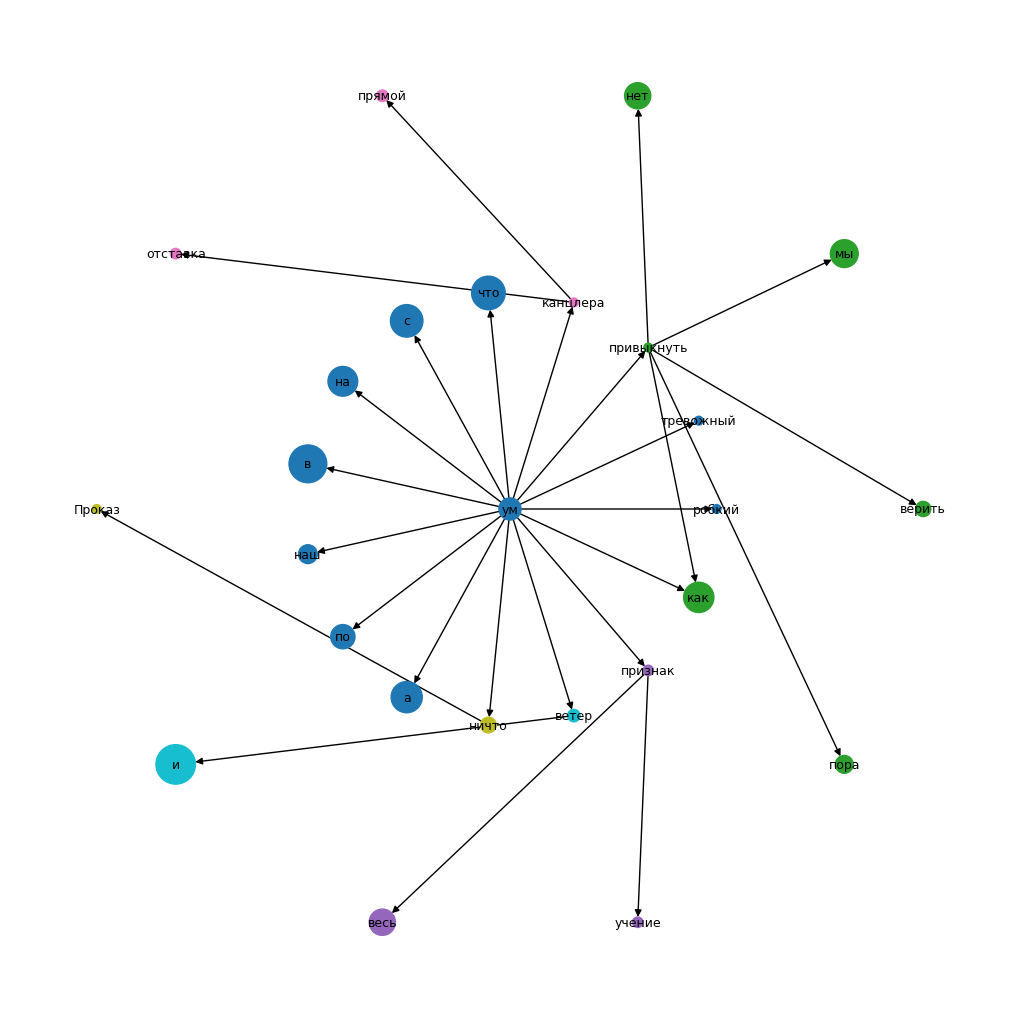

In [26]:
cmap = {n: i for i, c in enumerate(comms) for n in c}
plt.figure(figsize=(10, 10))
nx.draw(G, pos, with_labels=True, font_size=9, cmap=plt.cm.tab10,
        node_color=[cmap[n] for n in G],
        node_size=[40 * freq[n] ** 0.5 for n in G])
plt.show()

**Results**

- **26 nodes, 26 edges, density 0.04**: the graph is very sparse and almost a tree, as expected, since every word has one syntactic head. A tree with 26 nodes has 25 edges, so there is exactly one extra edge.
- **Avrage clustering 0.041**: that extra edge creates the only triangle. *как* depends both on *ум* and on *привыкнуть*.
- **Degree and betweenness**: *ум* dominates by construction (betweenness 0.92). The main secondary hub is *привыкнуть* (6 neighbours, betweenness 0.30), followed by *признак* and *канцлера*. Most direct dependents (*с, на, в, по, наш*) have no dependents of their own.
- **Communities** (modularity 0.355): there are 6 communities. The largest is *ум* with its leaf dependents (prepositions, *наш*, *что*, *робкий*, *тревожный*). Each of the others is a single branch, e.g. *привыкнуть + как, мы, нет, пора, верить*. Modularity above 0.3 formally indicates structure, but here it reflects the tree shape rather than distinct constructions.

### 6. Conclusions

*ум* occurs mostly in prepositional phrases. The thickest edge *ум → с* reflects the idiom *с ума* (*сойти / свести с ума*), followed by *на уме* and *в уме*. So the word is used largely in fixed expressions about madness or thoughts, which fits the theme of the play. Its few adjectives (*тревожный, робкий*) describe it emotionally.

Network measures add little beyond this: the graph is a sparse star-like tree, and its communities mirror single branches. The second level is also partly parser noise (unlemmatized *канцлера*, *Проказ*, the dubious head *привыкнуть*), so conclusions about secondary dependencies should be concidered.